# Experimento 09g — Optimización final de hiperparámetros

Randomized Search para regresión logística, SVM lineal y Gradient Boosting, con selección temporal de variables al 50 %. Evaluamos entrenamiento hasta 2012 y validación 2013; después ampliamos entrenamiento año a año hasta validar 2016. Los años 2017 en adelante quedan reservados para la prueba final.

## 1. Método y control de fuga de información

En cada uno de los cuatro cortes, el porcentaje de faltantes se calcula exclusivamente en el tramo de entrenamiento. Se conservan variables con **50 % o menos** de faltantes y se excluyen las que superan ese límite, incluidas las totalmente vacías. La selección puede producir una cantidad distinta de variables en cada corte: se evalúa una regla que se vuelve a ajustar con los datos históricos disponibles, no una lista fija.

La imputación numérica, la codificación de categorías y el escalado también se ajustan solo con entrenamiento. En cada corte, un pipeline aplica selección y preparación; sus matrices se reutilizan para todas las configuraciones, asegurando los mismos préstamos y las mismas características entre candidatos. `ParameterSampler` sortea combinaciones de hiperparámetros, mientras que los índices temporales se mantienen fijos. Esto evita que el año validado influya en la selección, las medianas o la codificación.

La búsqueda es una comparación de desarrollo sobre cuatro años ya utilizados para decisiones del proyecto. Elegir el mejor candidato a partir de esos mismos años puede favorecerlo; por eso no llamamos óptimos universales a los parámetros elegidos y mantenemos el test cerrado.

In [1]:
from pathlib import Path
import sys, time, gc, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.exceptions import ConvergenceWarning

RAIZ=Path.cwd()
if not (RAIZ/"src").exists(): RAIZ=RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0,str(RAIZ))
from src.config import localizar_datos, MAPA_OBJETIVO, SEMILLA
from src.modelado import TIPOS_AUDITADOS
from src import features as ft

SALIDA=RAIZ/"outputs"/"optimizacion_final"
SALIDA.mkdir(parents=True,exist_ok=True)
RUTA=localizar_datos()
ANIOS_VALIDACION=[2013,2014,2015,2016]
UMBRAL_FALTANTES=50
# Presupuesto total por modelo incluye una configuración anterior de referencia.
N_ALEATORIAS={"regresion_logistica":8,"svm_lineal":8,"gradient_boosting":10}
PARAMETROS_ANTERIORES={
 "regresion_logistica":{"C":0.13292918943162169,"class_weight":None,"tol":1e-4},
 "svm_lineal":{"C":0.010053940194693016,"class_weight":"balanced","tol":1e-4},
 "gradient_boosting":{"learning_rate":0.08118441500491742,"max_iter":182,"max_leaf_nodes":31,
  "min_samples_leaf":46,"l2_regularization":0.32877474139911184},
}
print("Archivo:",RUTA.name,"| umbral faltantes:",UMBRAL_FALTANTES,"| sorteos aleatorios:",N_ALEATORIAS)

Archivo: accepted_2007_to_2018Q4.csv.gz | umbral faltantes: 50 | sorteos aleatorios: {'regresion_logistica': 8, 'svm_lineal': 8, 'gradient_boosting': 10}


## 2. Carga de candidatas y exclusiones justificadas

Partimos de las candidatas anteriores al filtro de faltantes, aplicando las mismas reglas de alcance y disponibilidad al otorgamiento de 09e. `loan_status` solo define el objetivo, `issue_d` fija el año y las fechas de historial se transforman en antigüedad de crédito. No se incluyen identificadores, texto libre, variables de precio de Lending Club ni información posterior al otorgamiento. Los años posteriores a 2016 no entran en los datos cargados para la búsqueda.

In [2]:
columnas_fuente=pd.read_csv(RUTA,nrows=0).columns.tolist()
candidatas=ft.seleccionar_predictoras(pd.DataFrame(columns=columnas_fuente),[],incluir_precio_lc=False)
cols_lectura=list(dict.fromkeys(candidatas+["loan_status","issue_d"]))
dtypes={c:("string" if TIPOS_AUDITADOS.get(c) in ["category","string"] else TIPOS_AUDITADOS.get(c,"string")) for c in cols_lectura}
partes=[]; filas_leidas=0; t0=time.perf_counter()
with pd.read_csv(RUTA,usecols=cols_lectura,dtype=dtypes,chunksize=100_000,skipinitialspace=True,low_memory=False) as lector:
    for k,bloque in enumerate(lector,1):
        filas_leidas+=len(bloque)
        issue=pd.to_datetime(bloque["issue_d"],format="%b-%Y",errors="coerce")
        mask=issue.notna()&(issue.dt.year<=2016)&bloque.loan_status.isin(MAPA_OBJETIVO)
        bloque=bloque.loc[mask].copy(); issue=issue.loc[mask]
        if bloque.empty: continue
        for c in ["earliest_cr_line","sec_app_earliest_cr_line"]:
            if c in bloque:
                originales=bloque[c].notna()
                converted=pd.to_datetime(bloque[c],format="%b-%Y",errors="coerce")
                if (originales&converted.isna()).any(): raise ValueError(f"Fecha no reconocida en {c}")
                bloque[c]=converted
        if "term" in bloque:
            bloque["term"]=pd.to_numeric(bloque.term.astype("string").str.strip().str.replace(" months","",regex=False),errors="raise").astype("float64")
        bloque["fecha_prestamo"]=issue
        bloque["anio"]=issue.dt.year.astype("int16")
        bloque["default"]=bloque.loan_status.map(MAPA_OBJETIVO).astype("int8")
        partes.append(bloque)
        if k%10==0: print(f"Bloques leídos: {k}; filas fuente: {filas_leidas:,}",flush=True)
datos=pd.concat(partes,ignore_index=True)
assert datos.anio.max()<=2016, "Hay datos posteriores a 2016 en la búsqueda."
assert datos.loan_status.isin(MAPA_OBJETIVO).all()
print(f"Población elegible cargada: {len(datos):,}; años {datos.anio.min()}–{datos.anio.max()}; candidatas: {len(candidatas)}; lectura {time.perf_counter()-t0:.1f}s")

# Verificar categorías de exclusión conocidas en las candidatas.
posteriores=set(ft.columnas_posteriores(columnas_fuente))
ids=set(ft.IDENTIFICADORES); texto=set(ft.TEXTO_LIBRE); precio=set(ft.PRECIO_LC)
assert not (set(candidatas)&(posteriores|ids|texto|precio)), "Una columna fuera de alcance se coló entre las candidatas."
print("Verificación: loan_status/issue_d no son predictoras y no hay columnas post-otorgamiento entre las candidatas.")
print("Años disponibles para CV:",sorted(datos.anio.unique()))

Bloques leídos: 10; filas fuente: 1,000,000


Bloques leídos: 20; filas fuente: 2,000,000


Población elegible cargada: 1,119,699; años 2007–2016; candidatas: 95; lectura 93.7s
Verificación: loan_status/issue_d no son predictoras y no hay columnas post-otorgamiento entre las candidatas.
Años disponibles para CV: [np.int16(2007), np.int16(2008), np.int16(2009), np.int16(2010), np.int16(2011), np.int16(2012), np.int16(2013), np.int16(2014), np.int16(2015), np.int16(2016)]


## 3. Cortes temporales y pipeline por corte

Antes de entrenar, se construyen los índices de los cuatro cortes. Se confirma que entrenamiento y validación no se solapan en el tiempo. El selector se ajusta en cada entrenamiento y registra los porcentajes faltantes y nombres originales. Luego se aplican mediana, «Sin información», One-Hot Encoding y escalado según el modelo. No se usan filas aleatorias.

In [3]:
# Transformación determinista de fechas por observación; no aprende estadísticas.
X_cv=datos[candidatas].copy()
for c in ["earliest_cr_line","sec_app_earliest_cr_line"]:
    if c in X_cv:
        inicio=X_cv[c]; fecha=datos.fecha_prestamo
        X_cv["meses_desde_"+c]=((fecha.dt.year-inicio.dt.year)*12+(fecha.dt.month-inicio.dt.month)).astype("float64")
        X_cv=X_cv.drop(columns=c)
for c in X_cv:
    if pd.api.types.is_numeric_dtype(X_cv[c]):
        X_cv[c]=pd.to_numeric(X_cv[c],errors="coerce").astype("float64").replace([np.inf,-np.inf],np.nan)
    else:
        X_cv[c]=X_cv[c].astype(object).where(X_cv[c].notna(),np.nan)
y_cv=datos.default.to_numpy(dtype="int8")
anios_cv=datos.anio.to_numpy()
cv_temporal=[]
for anio in ANIOS_VALIDACION:
    itr=np.flatnonzero(anios_cv<anio); iva=np.flatnonzero(anios_cv==anio)
    assert len(itr)>0 and len(iva)>0
    assert anios_cv[itr].max()<anio and np.all(anios_cv[iva]==anio)
    cv_temporal.append((itr,iva))
print("Cortes:",[(int(anios_cv[tr].min()),int(anios_cv[tr].max()),int(anios_cv[va][0]),len(tr),len(va)) for tr,va in cv_temporal])

class SelectorFaltantes(BaseEstimator,TransformerMixin):
    """Selecciona columnas solo con los faltantes de su ajuste de entrenamiento."""
    def __init__(self, max_faltantes_pct=50): self.max_faltantes_pct=max_faltantes_pct
    def fit(self,X,y=None):
        self.columnas_entrada_=list(X.columns)
        self.porcentaje_faltantes_=(X.isna().mean()*100)
        self.columnas_seleccionadas_=[c for c in self.columnas_entrada_
            if self.porcentaje_faltantes_[c]<=self.max_faltantes_pct and X[c].notna().any()]
        if not self.columnas_seleccionadas_: raise ValueError("El corte dejó cero predictoras.")
        return self
    def transform(self,X): return X.loc[:,self.columnas_seleccionadas_]
    def get_feature_names_out(self,input_features=None): return np.asarray(self.columnas_seleccionadas_,dtype=object)

class PreprocesadorFold(BaseEstimator,TransformerMixin):
    """Imputa y codifica con estadísticas aprendidas únicamente en el entrenamiento."""
    def __init__(self,denso=False): self.denso=denso
    def fit(self,X,y=None):
        self.numericas_=[c for c in X if pd.api.types.is_numeric_dtype(X[c])]
        self.categoricas_=[c for c in X if c not in self.numericas_]
        transformadores=[]
        if self.numericas_:
            transformadores.append(("numericas",Pipeline([
                ("imputar",SimpleImputer(strategy="median")),
                ("escalar",StandardScaler(with_mean=self.denso)),
            ]),self.numericas_))
        if self.categoricas_:
            transformadores.append(("categoricas",Pipeline([
                ("imputar",SimpleImputer(strategy="constant",fill_value="Sin información")),
                ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=not self.denso,dtype=np.float32)),
            ]),self.categoricas_))
        self.preprocesador_=ColumnTransformer(transformadores,remainder="drop",sparse_threshold=0.0 if self.denso else 1.0)
        self.preprocesador_.fit(X,y)
        return self
    def transform(self,X): return self.preprocesador_.transform(X)

def construir_pipeline_preparacion(denso=False):
    return Pipeline([("seleccion",SelectorFaltantes(UMBRAL_FALTANTES)),("preprocesamiento",PreprocesadorFold(denso=denso))])


Cortes: [(2007, 2012, 2013, 93153, 134804), (2007, 2013, 2014, 227957, 223102), (2007, 2014, 2015, 451059, 375545), (2007, 2015, 2016, 826604, 293095)]


## 4. Espacios de búsqueda y configuraciones de referencia

Los espacios amplían los rangos del experimento 08: `C` en escala logarítmica para los modelos lineales; tasa de aprendizaje, iteraciones, hojas, tamaño mínimo de hoja y regularización para Gradient Boosting. Los sorteos son reproducibles. Se conserva una configuración ganadora anterior por algoritmo como candidato explícito; el total indicado incluye esa referencia. Tras una primera ejecución interrumpida por duración, el presupuesto se fija en 8/8/10 sorteos más una referencia previa por modelo (116 ajustes configuración-corte). Es menor que la orientación 20/20/40, pero conserva cuatro cortes para cada candidato; los resultados se guardan después de cada configuración y el proceso puede retomarse desde esos checkpoints. Los rangos se acotan a valores razonables de las búsquedas previas para evitar combinaciones extremas muy costosas.

In [4]:
espacios={
 "regresion_logistica":{
    "C":loguniform(1e-3,1e1),"class_weight":[None,"balanced"],"tol":loguniform(5e-5,1e-3)},
 "svm_lineal":{
    "C":loguniform(1e-3,1e1),"class_weight":[None,"balanced"],"tol":loguniform(5e-5,1e-3)},
 "gradient_boosting":{
    "learning_rate":loguniform(0.02,0.16),"max_iter":randint(100,201),
    "max_leaf_nodes":randint(7,34),"min_samples_leaf":randint(25,91),
    "l2_regularization":loguniform(0.05,10.0)},
}

def muestrear_configuraciones(modelo):
    aleatorias=list(ParameterSampler(espacios[modelo],n_iter=N_ALEATORIAS[modelo],random_state=SEMILLA))
    configs=[dict(PARAMETROS_ANTERIORES[modelo])]+[dict(x) for x in aleatorias]
    # Eliminar duplicados exactos y conservar un total reproducible si se diera una coincidencia.
    unicas=[]; claves=set()
    for c in configs:
        k=json.dumps(c,sort_keys=True,default=str)
        if k not in claves: unicas.append(c); claves.add(k)
    return unicas

configuraciones={m:muestrear_configuraciones(m) for m in espacios}
print("Configuraciones totales con referencia incluida:",{m:len(c) for m,c in configuraciones.items()})
print("Ajustes previstos:",sum(len(c) for c in configuraciones.values())*len(cv_temporal))
for m,cs in configuraciones.items():
    print(m,"| config. 1 = referencia previa:",cs[0])


def crear_modelo(nombre,params):
    if nombre=="regresion_logistica":
        return LogisticRegression(**params,solver="lbfgs",max_iter=3000,random_state=SEMILLA)
    if nombre=="svm_lineal":
        return LinearSVC(**params,dual="auto",max_iter=7000,random_state=SEMILLA)
    if nombre=="gradient_boosting":
        return HistGradientBoostingClassifier(**params,early_stopping=False,random_state=SEMILLA)
    raise ValueError(nombre)

def puntuacion_continua(modelo,nombre,X):
    return modelo.predict_proba(X)[:,1] if nombre in ["regresion_logistica","gradient_boosting"] else modelo.decision_function(X)


Configuraciones totales con referencia incluida: {'regresion_logistica': 9, 'svm_lineal': 9, 'gradient_boosting': 11}
Ajustes previstos: 116
regresion_logistica | config. 1 = referencia previa: {'C': 0.13292918943162169, 'class_weight': None, 'tol': 0.0001}
svm_lineal | config. 1 = referencia previa: {'C': 0.010053940194693016, 'class_weight': 'balanced', 'tol': 0.0001}
gradient_boosting | config. 1 = referencia previa: {'learning_rate': 0.08118441500491742, 'max_iter': 182, 'max_leaf_nodes': 31, 'min_samples_leaf': 46, 'l2_regularization': 0.32877474139911184}


## 5. Randomized Search con los cuatro cortes

Se genera una configuración anterior y un conjunto reproducible de nuevas configuraciones sorteadas por modelo. Para cada corte se ajustan los pipelines de selección e imputación solo en entrenamiento. Todas las configuraciones de un modelo usan exactamente esas mismas matrices de ese corte. La puntuación se calcula con `predict_proba` para regresión logística y Gradient Boosting y con `decision_function` para SVM. ROC-AUC es el criterio de ordenamiento; PR-AUC y dispersión anual quedan como medidas complementarias.

In [5]:
resultados_path=SALIDA/"checkpoint_resultados_por_corte.csv"
seleccion_path=SALIDA/"checkpoint_variables_por_corte.csv"
resultados=(pd.read_csv(resultados_path).to_dict("records") if resultados_path.exists() else [])
seleccion_por_corte=(pd.read_csv(seleccion_path).to_dict("records") if seleccion_path.exists() else [])
completados={(r["modelo"],int(r["configuracion"]),int(r["anio_validacion"])) for r in resultados}

def guardar_checkpoint():
    pd.DataFrame(resultados).to_csv(resultados_path,index=False,encoding="utf-8-sig")
    pd.DataFrame(seleccion_por_corte).drop_duplicates(["anio_validacion","variable_modelo"]).to_csv(seleccion_path,index=False,encoding="utf-8-sig")

inicio_busqueda=time.perf_counter()
for numero_corte,(itr,iva) in enumerate(cv_temporal):
    anio=ANIOS_VALIDACION[numero_corte]
    tareas_pendientes=[(m,i) for m,cs in configuraciones.items() for i in range(1,len(cs)+1)
                       if (m,i,anio) not in completados]
    if not tareas_pendientes:
        print(f"Corte {anio}: ya estaba completo; se reutiliza el checkpoint.",flush=True)
        continue
    Xtr=X_cv.iloc[itr]; Xva=X_cv.iloc[iva]; ytr=y_cv[itr]; yva=y_cv[iva]
    pipe_lineal=construir_pipeline_preparacion(denso=False)
    Xt_lin=pipe_lineal.fit_transform(Xtr,ytr); Xv_lin=pipe_lineal.transform(Xva)
    sel=pipe_lineal.named_steps["seleccion"]
    pct=sel.porcentaje_faltantes_; columnas=sel.columnas_seleccionadas_
    assert all(pct[c]<=UMBRAL_FALTANTES for c in columnas)
    assert all(pct[c]>UMBRAL_FALTANTES or not Xtr[c].notna().any() for c in Xtr.columns if c not in columnas)
    if not any(int(r["anio_validacion"])==anio for r in seleccion_por_corte):
        for c in Xtr.columns:
            original="earliest_cr_line" if c=="meses_desde_earliest_cr_line" else c
            if c=="meses_desde_sec_app_earliest_cr_line": original="sec_app_earliest_cr_line"
            seleccion_por_corte.append({"anio_validacion":anio,"anio_final_entrenamiento":anio-1,
                "variable_modelo":c,"variable_fuente":original,"faltante_pct_entrenamiento":float(pct[c]),
                "seleccionada":c in columnas,"decision":"conservar" if c in columnas else "excluir"})
        guardar_checkpoint()
    print(f"Corte {anio}: {len(columnas)} predictoras; train {len(ytr):,}, validación {len(yva):,}; faltan {len(tareas_pendientes)} ajustes.",flush=True)
    assert Xt_lin.shape[0]==len(ytr) and Xv_lin.shape[0]==len(yva) and len(np.unique(yva))==2
    for nombre in ["regresion_logistica","svm_lineal"]:
        for numero_config,params in enumerate(configuraciones[nombre],1):
            llave=(nombre,numero_config,anio)
            if llave in completados: continue
            clf=crear_modelo(nombre,params); t=time.perf_counter()
            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always",ConvergenceWarning); clf.fit(Xt_lin,ytr)
            score=puntuacion_continua(clf,nombre,Xv_lin); segundos=time.perf_counter()-t
            resultados.append({"modelo":nombre,"configuracion":numero_config,
                "tipo_configuracion":"anterior" if numero_config==1 else "aleatoria",
                "hiperparametros":json.dumps(params,sort_keys=True,default=lambda z:z.item() if hasattr(z,"item") else str(z)),
                "anio_validacion":anio,"filas_entrenamiento":len(ytr),"filas_validacion":len(yva),
                "variables_originales":len(columnas),"columnas_transformadas":Xt_lin.shape[1],
                "ROC_AUC":roc_auc_score(yva,score),"PR_AUC":average_precision_score(yva,score),
                "segundos_ajuste":segundos,"advertencia_convergencia":any(isinstance(w.message,ConvergenceWarning) for w in avisos)})
            completados.add(llave); guardar_checkpoint(); del clf,score
        gc.collect()
    del pipe_lineal,Xt_lin,Xv_lin
    pendientes_gb=[i for i in range(1,len(configuraciones["gradient_boosting"])+1)
                   if ("gradient_boosting",i,anio) not in completados]
    if pendientes_gb:
        pipe_gb=construir_pipeline_preparacion(denso=True)
        Xt_gb=pipe_gb.fit_transform(Xtr,ytr); Xv_gb=pipe_gb.transform(Xva)
        sel_gb=pipe_gb.named_steps["seleccion"]
        assert sel_gb.columnas_seleccionadas_==columnas
        assert Xt_gb.shape[0]==len(ytr) and Xv_gb.shape[0]==len(yva)
        for numero_config,params in enumerate(configuraciones["gradient_boosting"],1):
            llave=("gradient_boosting",numero_config,anio)
            if llave in completados: continue
            clf=crear_modelo("gradient_boosting",params); t=time.perf_counter(); clf.fit(Xt_gb,ytr)
            score=clf.predict_proba(Xv_gb)[:,1]; segundos=time.perf_counter()-t
            resultados.append({"modelo":"gradient_boosting","configuracion":numero_config,
                "tipo_configuracion":"anterior" if numero_config==1 else "aleatoria",
                "hiperparametros":json.dumps(params,sort_keys=True,default=lambda z:z.item() if hasattr(z,"item") else str(z)),
                "anio_validacion":anio,"filas_entrenamiento":len(ytr),"filas_validacion":len(yva),
                "variables_originales":len(columnas),"columnas_transformadas":Xt_gb.shape[1],
                "ROC_AUC":roc_auc_score(yva,score),"PR_AUC":average_precision_score(yva,score),
                "segundos_ajuste":segundos,"advertencia_convergencia":False})
            completados.add(llave); guardar_checkpoint(); del clf,score
        del pipe_gb,Xt_gb,Xv_gb
    del Xtr,Xva,ytr,yva
    gc.collect()
    print(f"Corte {anio} guardado: {sum(r['anio_validacion']==anio for r in resultados)} resultados.",flush=True)

resultados=pd.DataFrame(resultados).drop_duplicates(["modelo","configuracion","anio_validacion"])
seleccion_por_corte=pd.DataFrame(seleccion_por_corte).drop_duplicates(["anio_validacion","variable_modelo"])
assert len(resultados)==sum(len(c) for c in configuraciones.values())*4, f"Faltan resultados: {len(resultados)}"
assert set(resultados.anio_validacion)==set(ANIOS_VALIDACION)
print(f"Búsqueda ejecutada: {len(resultados):,} resultados configuración-corte en {(time.perf_counter()-inicio_busqueda)/60:.1f} min.")
print("Configuraciones de cada corte recibieron mismos préstamos y mismas columnas originales; selector y preprocesamiento se ajustaron solo en train.")
resultados.to_csv(SALIDA/"resultados_por_configuracion_y_corte.csv",index=False,encoding="utf-8-sig")
seleccion_por_corte.to_csv(SALIDA/"seleccion_variables_por_corte.csv",index=False,encoding="utf-8-sig")


Corte 2013: ya estaba completo; se reutiliza el checkpoint.


Corte 2014: ya estaba completo; se reutiliza el checkpoint.


Corte 2015: ya estaba completo; se reutiliza el checkpoint.


Corte 2016: 60 predictoras; train 826,604, validación 293,095; faltan 29 ajustes.


Corte 2016 guardado: 29 resultados.


Búsqueda ejecutada: 116 resultados configuración-corte en 38.6 min.
Configuraciones de cada corte recibieron mismos préstamos y mismas columnas originales; selector y preprocesamiento se ajustaron solo en train.


## 6. Resumen, mejores configuraciones y comparación con la referencia

Cada configuración se resume con promedio y desviación estándar de cuatro cortes. El primer candidato de cada modelo es la configuración optimizada en la búsqueda anterior y se puntúa de nuevo con selección al 50 % para que la comparación sea equivalente. El ganador se elige por ROC-AUC promedio; en caso de valores cercanos se inspeccionan PR-AUC, estabilidad y sencillez.

Todas las configuraciones evaluadas (ordenadas por ROC-AUC promedio dentro de cada modelo):


,modelo,configuracion,tipo_configuracion,hiperparametros,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_promedio,segundos_totales,advertencias_convergencia
0,gradient_boosting,8,aleatoria,"{""l2_regularization"": 9.149845592811953, ""lear...",0.71049,0.02457,0.36953,0.07437,51.5,88.02159,0
1,gradient_boosting,1,anterior,"{""l2_regularization"": 0.32877474139911184, ""le...",0.71043,0.02591,0.36869,0.07690,51.5,81.96757,0
2,gradient_boosting,7,aleatoria,"{""l2_regularization"": 0.5602743212524077, ""lea...",0.71026,0.02524,0.36911,0.07539,51.5,54.53389,0
3,gradient_boosting,10,aleatoria,"{""l2_regularization"": 0.9888105463079512, ""lea...",0.70908,0.02451,0.36786,0.07429,51.5,85.14873,0
4,gradient_boosting,5,aleatoria,"{""l2_regularization"": 0.8062139229281309, ""lea...",0.70892,0.02402,0.36784,0.07334,51.5,76.81747,0
5,gradient_boosting,2,aleatoria,"{""l2_regularization"": 0.36374585440139057, ""le...",0.70853,0.02742,0.36567,0.07840,51.5,57.27489,0
6,gradient_boosting,11,aleatoria,"{""l2_regularization"": 1.8767685726165642, ""lea...",0.70788,0.02390,0.36674,0.07295,51.5,64.80942,0
7,gradient_boosting,3,aleatoria,"{""l2_regularization"": 1.572837678363309, ""lear...",0.70163,0.02190,0.35962,0.06898,51.5,73.03704,0
8,gradient_boosting,6,aleatoria,"{""l2_regularization"": 0.4159700806131841, ""lea...",0.70048,0.02171,0.35832,0.06844,51.5,70.82392,0
9,gradient_boosting,9,aleatoria,"{""l2_regularization"": 0.12341022039945063, ""le...",0.69707,0.02088,0.35459,0.06660,51.5,53.98708,0


Mejor configuración explorada por modelo:


,modelo,configuracion,tipo_configuracion,hiperparametros,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_promedio,segundos_totales,advertencias_convergencia
0,gradient_boosting,8,aleatoria,"{""l2_regularization"": 9.149845592811953, ""lear...",0.71049,0.02457,0.36953,0.07437,51.5,88.02159,0
1,regresion_logistica,2,aleatoria,"{""C"": 0.03148911647956861, ""class_weight"": nul...",0.70235,0.02371,0.35948,0.07089,51.5,173.80181,0
2,svm_lineal,1,anterior,"{""C"": 0.010053940194693016, ""class_weight"": ""b...",0.70221,0.02414,0.35857,0.07108,51.5,174.06006,0


Referencia anterior vs. mejor configuración sorteada:

,modelo,ROC_AUC_anterior,PR_AUC_anterior,ROC_AUC_std_anterior,ROC_AUC_mejor,PR_AUC_mejor,ROC_AUC_std_mejor,delta_ROC_AUC,delta_PR_AUC
0,regresion_logistica,0.70219,0.35932,0.02386,0.70235,0.35948,0.02371,0.00016,0.00016
1,svm_lineal,0.70221,0.35857,0.02414,0.70221,0.35857,0.02414,0.00000,0.00000
2,gradient_boosting,0.71043,0.36869,0.02591,0.71049,0.36953,0.02457,0.00006,0.00084


,modelo,anio_validacion,ROC_AUC_anterior,ROC_AUC_mejor,delta_ROC_AUC,PR_AUC_anterior,PR_AUC_mejor,delta_PR_AUC
0,regresion_logistica,2013,0.66969,0.67010,0.00040,0.26307,0.26353,0.00046
1,regresion_logistica,2014,0.70532,0.70553,0.00020,0.34837,0.34855,0.00018
2,regresion_logistica,2015,0.72714,0.72721,0.00007,0.40835,0.40847,0.00011
3,regresion_logistica,2016,0.70659,0.70657,-0.00002,0.41749,0.41738,-0.00011
4,svm_lineal,2013,0.66941,0.66941,0.00000,0.26226,0.26226,0.00000
5,svm_lineal,2014,0.70589,0.70589,0.00000,0.34780,0.34780,0.00000
6,svm_lineal,2015,0.72760,0.72760,0.00000,0.40815,0.40815,0.00000
7,svm_lineal,2016,0.70596,0.70596,0.00000,0.41607,0.41607,0.00000
8,gradient_boosting,2013,0.67459,0.67677,0.00218,0.26500,0.26852,0.00352
9,gradient_boosting,2014,0.71317,0.71456,0.00139,0.35615,0.35891,0.00276


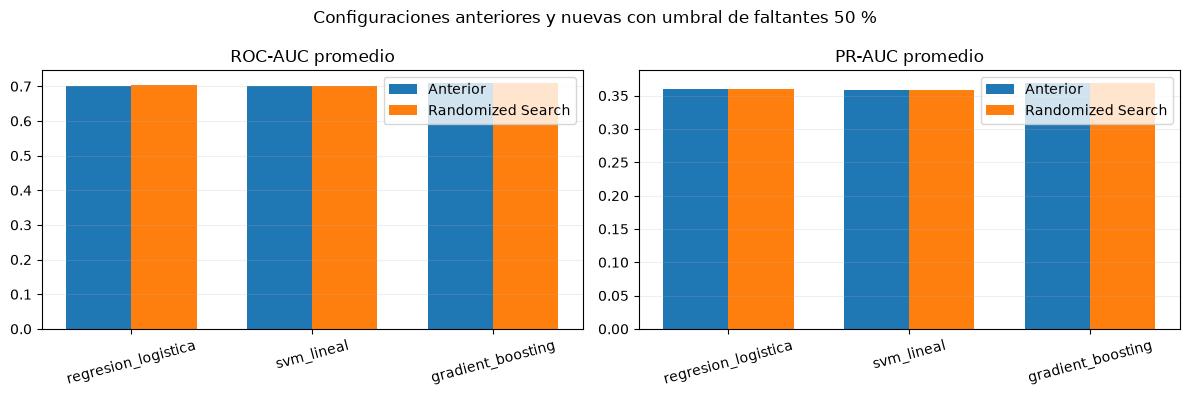

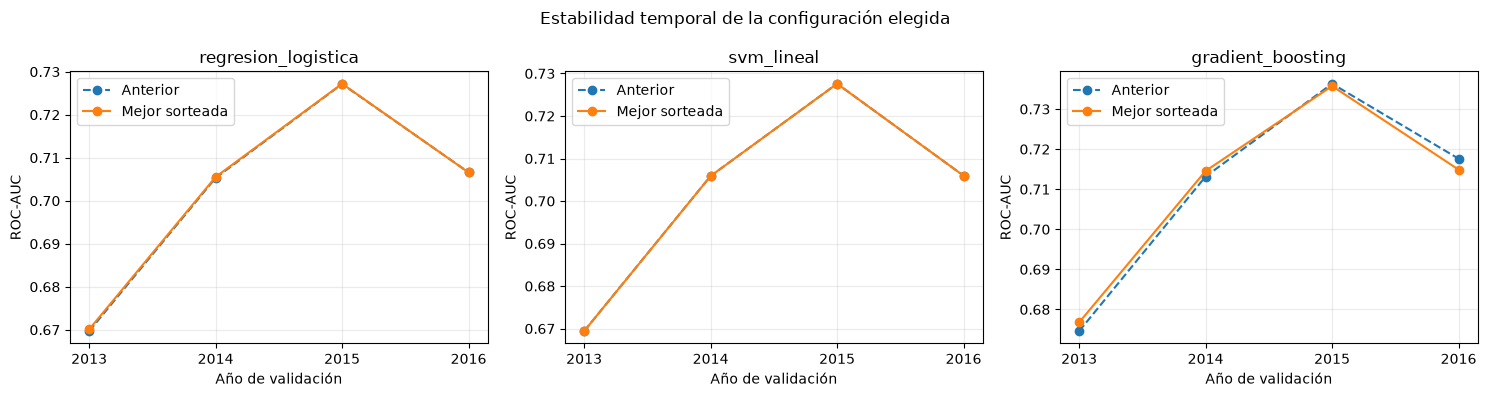

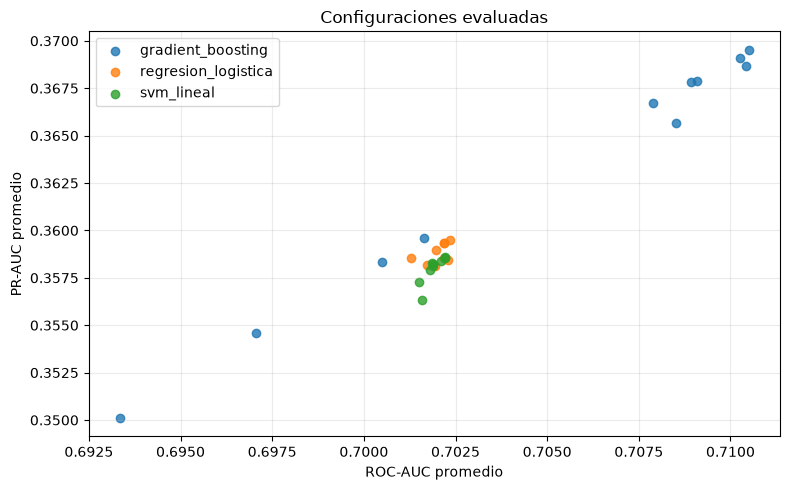

In [6]:
resumen=(resultados.groupby(["modelo","configuracion","tipo_configuracion","hiperparametros"],as_index=False)
 .agg(ROC_AUC_promedio=("ROC_AUC","mean"),ROC_AUC_desviacion=("ROC_AUC","std"),
      PR_AUC_promedio=("PR_AUC","mean"),PR_AUC_desviacion=("PR_AUC","std"),
      variables_promedio=("variables_originales","mean"),segundos_totales=("segundos_ajuste","sum"),
      advertencias_convergencia=("advertencia_convergencia","sum")))
resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]]=resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]].fillna(0)
resumen=resumen.sort_values(["modelo","ROC_AUC_promedio","PR_AUC_promedio"],ascending=[True,False,False]).reset_index(drop=True)
mejores=resumen.groupby("modelo",as_index=False,sort=False).first()
print("Todas las configuraciones evaluadas (ordenadas por ROC-AUC promedio dentro de cada modelo):")
display(resumen.round(5))
print("Mejor configuración explorada por modelo:")
display(mejores.round(5))

# Tabla de referencia previa frente al candidato elegido bajo exactamente la misma selección 50% y los mismos cortes.
comparaciones=[]; anual=[]
for modelo in configuraciones:
    base=resultados[(resultados.modelo==modelo)&(resultados.configuracion==1)].sort_values("anio_validacion")
    mejor=mejores[mejores.modelo==modelo].iloc[0]
    nueva=resultados[(resultados.modelo==modelo)&(resultados.configuracion==mejor.configuracion)].sort_values("anio_validacion")
    comparaciones.append({"modelo":modelo,"ROC_AUC_anterior":base.ROC_AUC.mean(),"PR_AUC_anterior":base.PR_AUC.mean(),
        "ROC_AUC_std_anterior":base.ROC_AUC.std(),"ROC_AUC_mejor":nueva.ROC_AUC.mean(),"PR_AUC_mejor":nueva.PR_AUC.mean(),
        "ROC_AUC_std_mejor":nueva.ROC_AUC.std(),"delta_ROC_AUC":nueva.ROC_AUC.mean()-base.ROC_AUC.mean(),
        "delta_PR_AUC":nueva.PR_AUC.mean()-base.PR_AUC.mean(),"hiperparametros_mejores":mejor.hiperparametros})
    for _,(r0,r1) in enumerate(zip(base.itertuples(),nueva.itertuples())):
        anual.append({"modelo":modelo,"anio_validacion":r0.anio_validacion,"ROC_AUC_anterior":r0.ROC_AUC,
            "ROC_AUC_mejor":r1.ROC_AUC,"delta_ROC_AUC":r1.ROC_AUC-r0.ROC_AUC,
            "PR_AUC_anterior":r0.PR_AUC,"PR_AUC_mejor":r1.PR_AUC,"delta_PR_AUC":r1.PR_AUC-r0.PR_AUC})
comparacion=pd.DataFrame(comparaciones); comparacion_anual=pd.DataFrame(anual)
print("Referencia anterior vs. mejor configuración sorteada:"); display(comparacion.drop(columns="hiperparametros_mejores").round(5))
display(comparacion_anual.round(5))

# Configuraciones y selección guardadas para reproducir.
resumen.to_csv(SALIDA/"resumen_todas_configuraciones.csv",index=False,encoding="utf-8-sig")
mejores.to_csv(SALIDA/"mejores_parametros_por_modelo.csv",index=False,encoding="utf-8-sig")
comparacion.to_csv(SALIDA/"comparacion_anterior_vs_mejor.csv",index=False,encoding="utf-8-sig")
comparacion_anual.to_csv(SALIDA/"comparacion_por_anio.csv",index=False,encoding="utf-8-sig")
with open(SALIDA/"configuracion_reproducible.json","w",encoding="utf-8") as f:
    json.dump({"umbral_faltantes_train_pct":UMBRAL_FALTANTES,"anios_validacion":ANIOS_VALIDACION,
        "semilla":int(SEMILLA),"sorteos_aleatorios":N_ALEATORIAS,"parametros_referencia":PARAMETROS_ANTERIORES,
        "mejores_parametros":{r.modelo:json.loads(r.hiperparametros) for r in mejores.itertuples()}},f,ensure_ascii=False,indent=2)

# Visualizaciones de comparación y estabilidad anual.
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metrica,titulo in [(axes[0],"ROC_AUC_promedio","ROC-AUC promedio"),(axes[1],"PR_AUC_promedio","PR-AUC promedio")]:
    x=np.arange(3); modelos=list(configuraciones)
    base_vals=[comparacion.loc[comparacion.modelo==m,metrica.replace("_promedio","_anterior")].iloc[0] for m in modelos]
    best_vals=[comparacion.loc[comparacion.modelo==m,metrica.replace("_promedio","_mejor")].iloc[0] for m in modelos]
    ax.bar(x-.18,base_vals,.36,label="Anterior"); ax.bar(x+.18,best_vals,.36,label="Randomized Search")
    ax.set_xticks(x,labels=modelos,rotation=15); ax.set_title(titulo); ax.grid(axis="y",alpha=.2); ax.legend()
fig.suptitle("Configuraciones anteriores y nuevas con umbral de faltantes 50 %")
fig.tight_layout(); fig.savefig(SALIDA/"01_comparacion_modelos.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=False)
for ax,modelo in zip(axes,configuraciones):
    sub=comparacion_anual[comparacion_anual.modelo==modelo]
    ax.plot(sub.anio_validacion,sub.ROC_AUC_anterior,marker="o",linestyle="--",label="Anterior")
    ax.plot(sub.anio_validacion,sub.ROC_AUC_mejor,marker="o",label="Mejor sorteada")
    ax.set_title(modelo); ax.set_xticks(ANIOS_VALIDACION); ax.set_xlabel("Año de validación"); ax.set_ylabel("ROC-AUC"); ax.grid(alpha=.25); ax.legend()
fig.suptitle("Estabilidad temporal de la configuración elegida")
fig.tight_layout(); fig.savefig(SALIDA/"02_estabilidad_roc_por_anio.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
fig,ax=plt.subplots(figsize=(8,5))
for modelo,g in resumen.groupby("modelo"):
    ax.scatter(g.ROC_AUC_promedio,g.PR_AUC_promedio,label=modelo,alpha=.8)
ax.set(xlabel="ROC-AUC promedio",ylabel="PR-AUC promedio",title="Configuraciones evaluadas")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(SALIDA/"03_roc_vs_pr_configuraciones.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)


## 7. Conclusiones y límites de la búsqueda

La recomendación final se limita a las configuraciones sorteadas y a los cortes 2013–2016. No se ajustó umbral de decisión, no se calibraron probabilidades y no se usó el conjunto de prueba. La selección del candidato ganador sobre los mismos cuatro años puede hacer que su puntuación media sea optimista; se realizará una única evaluación final con los años reservados después de cerrar el modelo.

In [7]:
for modelo in configuraciones:
    g=resumen[resumen.modelo==modelo].sort_values("ROC_AUC_promedio",ascending=False)
    base=g[g.configuracion==1].iloc[0]; best=g.iloc[0]
    diff=best.ROC_AUC_promedio-base.ROC_AUC_promedio
    yearly=comparacion_anual[comparacion_anual.modelo==modelo]
    n_years=int((yearly.delta_ROC_AUC>0).sum())
    print(f"{modelo}: ROC-AUC {base.ROC_AUC_promedio:.5f} → {best.ROC_AUC_promedio:.5f} (Δ {diff:+.5f}); "
          f"PR-AUC {base.PR_AUC_promedio:.5f} → {best.PR_AUC_promedio:.5f}; "
          f"desv. ROC {best.ROC_AUC_desviacion:.5f}; mejora ROC en {n_years}/4 cortes.")
    print("  Parámetros elegidos:",best.hiperparametros)
print("\nVariables seleccionadas por corte:")
display(seleccion_por_corte.groupby(["anio_validacion","decision"]).size().unstack(fill_value=0).reset_index())
print("\nCautela: los hiperparámetros elegidos son los mejores entre los candidatos evaluados, no óptimos universales.")
print("La configuración ganadora se eligió por ROC-AUC promedio; PR-AUC y variación temporal se usan para interpretar diferencias cercanas.")

regresion_logistica: ROC-AUC 0.70219 → 0.70235 (Δ +0.00016); PR-AUC 0.35932 → 0.35948; desv. ROC 0.02371; mejora ROC en 3/4 cortes.
  Parámetros elegidos: {"C": 0.03148911647956861, "class_weight": null, "tol": 8.66211944751964e-05}
svm_lineal: ROC-AUC 0.70221 → 0.70221 (Δ +0.00000); PR-AUC 0.35857 → 0.35857; desv. ROC 0.02414; mejora ROC en 0/4 cortes.
  Parámetros elegidos: {"C": 0.010053940194693016, "class_weight": "balanced", "tol": 0.0001}
gradient_boosting: ROC-AUC 0.71043 → 0.71049 (Δ +0.00006); PR-AUC 0.36869 → 0.36953; desv. ROC 0.02457; mejora ROC en 2/4 cortes.
  Parámetros elegidos: {"l2_regularization": 9.149845592811953, "learning_rate": 0.05279087869966013, "max_iter": 200, "max_leaf_nodes": 25, "min_samples_leaf": 31}

Variables seleccionadas por corte:


decision,anio_validacion,conservar,excluir
0,2013,26,69
1,2014,60,35
2,2015,60,35
3,2016,60,35



Cautela: los hiperparámetros elegidos son los mejores entre los candidatos evaluados, no óptimos universales.
La configuración ganadora se eligió por ROC-AUC promedio; PR-AUC y variación temporal se usan para interpretar diferencias cercanas.


## Referencias metodológicas

- scikit-learn developers. (s. f.). *ParameterSampler*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ParameterSampler.html
- scikit-learn developers. (s. f.). *Pipeline and composite estimators*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/compose.html
- scikit-learn developers. (s. f.). *Time-related feature engineering and evaluation*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/cross_validation.html